# 06 最终结果对比

Edited by Li Yanyi, Wang Hongjie

核对并汇总第 04、05 步已保存的测试结果。


In [ ]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import hashlib
import logging
import os
import platform
import shutil
import sys
from dataclasses import dataclass
from datetime import datetime
from zoneinfo import ZoneInfo
import sklearn
import xgboost as xgb
from IPython.display import display

# Run from SP500; all notebook helpers are local.
ROOT = Path.cwd().resolve()
if not (ROOT / "01_data_preprocessing.ipynb").is_file():
    raise FileNotFoundError("Run this notebook from the SP500 directory.")


### 表格、图像与文件保存

保存 CSV/JSON，并在 Notebook 中展示结果。


In [ ]:
def display_path(path):
    """Show relative project paths and external filenames."""
    path = Path(path)
    if not path.is_absolute():
        return path.as_posix()
    try:
        return Path(os.path.relpath(path, ROOT)).as_posix()
    except ValueError:
        return path.name

def save_json(path, value):
    """Write UTF-8 JSON without nonstandard NaN or Infinity."""
    def convert(item):
        if isinstance(item, np.generic):
            return item.item()
        if isinstance(item, (Path, pd.Timestamp, datetime)):
            return str(item)
        raise TypeError(f"Cannot serialize {type(item)}")
    Path(path).write_text(
        json.dumps(value, ensure_ascii=False, indent=2, default=convert, allow_nan=False),
        encoding="utf-8",
    )

def save_csv(path, frame, index=True):
    frame.to_csv(path, index=index, encoding="utf-8-sig", index_label="signal_date" if index else None)

def file_hash(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def show_table(frame, decimals=4):
    """Display rounded values without changing saved data."""
    display(frame.round(decimals))

def show_figure(fig, path):
    """Save and display the figure."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    display(fig)
    plt.close(fig)


### 实验目录与逐轮训练日志

每次运行新建目录，保存配置、数据指纹、代码快照和逐轮日志。


In [ ]:
@dataclass
class Run:
    path: Path
    config: dict
    logger: logging.Logger

def start_run(name, config, sources):
    """Create a new run directory without overwriting results."""
    stamp = datetime.now(ZoneInfo("Asia/Singapore")).strftime("%Y%m%d_%H%M%S_%f")
    path = ROOT / "output" / name / stamp
    path.mkdir(parents=True, exist_ok=False)
    logger = logging.getLogger(f"{name}.{stamp}")
    logger.setLevel(logging.INFO)
    logger.propagate = False
    # Keep the notebook default warning format.
    fmt = logging.Formatter("%(asctime)s | %(message)s", datefmt="%H:%M:%S")
    for handler in (logging.FileHandler(path / "run.log", encoding="utf-8"), logging.StreamHandler(sys.stdout)):
        handler.setFormatter(fmt)
        logger.addHandler(handler)
    config = dict(config, scenario=name, created_at=datetime.now(ZoneInfo("Asia/Singapore")).isoformat())
    save_json(path / "config.json", config)
    save_json(path / "environment.json", {
        "python": platform.python_version(), "python_executable": sys.executable,
        "numpy": np.__version__, "pandas": pd.__version__, "scikit_learn": sklearn.__version__,
        "xgboost": xgb.__version__, "timezone": "Asia/Singapore",
    })
    save_json(path / "data_sources.json", [
        {"path": str(p), "sha256": file_hash(p), "bytes": p.stat().st_size}
        for p in sources
    ])
    snapshot = path / "code"
    snapshot.mkdir()
    for source in sorted(ROOT.glob("0[1-7]_*.ipynb")):
        if source.exists():
            shutil.copy2(source, snapshot / source.name)
    logger.info("Started %s; output directory %s", name, display_path(path))
    return Run(path, config, logger)


## 1. 选择已完成的运行
默认选择最新完整结果；复核旧运行时，可明确填写下面两个相对路径。


In [1]:
CLASSIFICATION_RUN = None  # Example: "output/classification_comparison/timestamp"
REGRESSION_RUN = None      # Example: "output/regression_comparison/timestamp"

def completed_run(scenario, explicit=None):
    """Use completed runs without relying on legacy results."""
    if explicit is not None:
        path = Path(explicit)
        candidates = [path if path.is_absolute() else ROOT / path]
    else:
        candidates = sorted((ROOT / "output" / scenario).glob("*"), reverse=True)
    for folder in candidates:
        status_file = folder / "status.json"
        if not status_file.is_file():
            continue
        status = json.loads(status_file.read_text(encoding="utf-8"))
        if status.get("status") == "completed" and (folder / "comparison_summary.csv").is_file():
            return folder
    raise FileNotFoundError(f"No complete {scenario} results; run the training notebook first.")

classification_run = completed_run("classification_comparison", CLASSIFICATION_RUN)  # Choose a completed classification run
regression_run = completed_run("regression_comparison", REGRESSION_RUN)  # Choose a completed regression run
print("Classification source:", classification_run.relative_to(ROOT))
print("Regression source:", regression_run.relative_to(ROOT))


Classification source: output\classification_comparison\20261123_220637_250154
Regression source: output\regression_comparison\20261123_220645_862295


## 2. 核查两方案使用相同测试样本
对每个任务核对信号日、入场日、结算日与真实标签；分类和回归之间不要求日期相同。


In [2]:
def read_comparison(folder, task):
    config = json.loads((folder / "config.json").read_text(encoding="utf-8"))
    if config["task"] != task:
        raise ValueError("Task does not match the result directory.")
    label = "target_class" if task == "classification" else "target_return"
    predictions = {}
    for arm in ("baseline", "final"):
        predictions[arm] = pd.read_csv(folder / arm / "test_predictions.csv",
                                      index_col="signal_date",
                                      parse_dates=["signal_date", "trade_date", "settle_date"])
    columns = ["trade_date", "settle_date", label]
    pd.testing.assert_frame_equal(predictions["baseline"][columns], predictions["final"][columns])  # Require matched test examples within each task
    table = pd.read_csv(folder / "comparison_summary.csv")
    assert len(table) == 2 and table["n_test"].eq(len(predictions["baseline"])).all()
    # Saved runs may use older labels; arm order is baseline, then final.
    labels = (["Arm A · 6 features + XGBoost", "Arm B · 11 features + XGBoost"]
              if task == "classification" else
              ["Baseline · 6 features + XGBoost", "Final · 6 features + Ridge"])
    table["scenario"] = labels
    split_summary = pd.read_csv(folder / "split_summary.csv")
    return table, split_summary

classification, classification_split = read_comparison(classification_run, "classification")
regression, regression_split = read_comparison(regression_run, "regression")
classification_metrics = ["scenario", "n_test", "roc_auc", "ap", "accuracy", "balanced_accuracy", "f1"]
regression_metrics = ["scenario", "n_test", "mae_bp", "rmse_bp", "r2", "constant_rmse_bp", "delta_rmse_bp"]
show_table(classification[classification_metrics])
show_table(regression[regression_metrics])


,scenario,n_test,roc_auc,ap,accuracy,balanced_accuracy,f1
0,Arm A · 6 features + XGBoost,449,0.5426,0.4631,0.5301,0.5307,0.4866
1,Arm B · 11 features + XGBoost,449,0.5576,0.4602,0.5523,0.5682,0.5523


,scenario,n_test,mae_bp,rmse_bp,r2,constant_rmse_bp,delta_rmse_bp
0,Baseline · 6 features + XGBoost,752,62.3551,92.6746,0.0048,92.9958,-0.3212
1,Final · 6 features + Ridge,752,62.3406,92.4969,0.0086,92.9958,-0.4989


## 3. 保存对比表与差值
差值统一为“final − baseline”。分类 AUC、AP 等越高越好；回归 MAE、RMSE 越低越好。


In [3]:
sources = [folder / file for folder in (classification_run, regression_run)
           for file in ("comparison_summary.csv", "split_summary.csv", "config.json")]
RUN = start_run("final_comparison", {
    "classification_run": classification_run.relative_to(ROOT).as_posix(),
    "regression_run": regression_run.relative_to(ROOT).as_posix(),
    "delta": "final minus baseline", "retraining": False,
}, sources)
save_csv(RUN.path / "classification_comparison.csv", classification, index=False)
save_csv(RUN.path / "regression_comparison.csv", regression, index=False)
delta_rows = []
for task, table, metrics in (
    ("classification", classification, ["roc_auc", "ap", "accuracy", "balanced_accuracy", "f1"]),
    ("regression", regression, ["mae_bp", "rmse_bp", "r2"]),
):
    for metric in metrics:
        base, final = float(table.iloc[0][metric]), float(table.iloc[1][metric])
        delta_rows.append({"task": task, "metric": metric, "baseline": base, "final": final,
                           "delta_final_minus_baseline": final - base,
                           "better_direction": "lower" if metric in ("mae_bp", "rmse_bp") else "higher"})
deltas = pd.DataFrame(delta_rows)
save_csv(RUN.path / "metric_differences.csv", deltas, index=False)
show_table(deltas)


22:06:51 | Started final_comparison; output directory output/final_comparison/20261123_220651_400227


,task,metric,baseline,final,delta_final_minus_baseline,better_direction
0,classification,roc_auc,0.5426,0.5576,0.0150,higher
1,classification,ap,0.4631,0.4602,-0.0028,higher
2,classification,accuracy,0.5301,0.5523,0.0223,higher
3,classification,balanced_accuracy,0.5307,0.5682,0.0375,higher
4,classification,f1,0.4866,0.5523,0.0657,higher
5,regression,mae_bp,62.3551,62.3406,-0.0145,lower
6,regression,rmse_bp,92.6746,92.4969,-0.1778,lower
7,regression,r2,0.0048,0.0086,0.0038,higher


## 4. 分类与回归分图展示


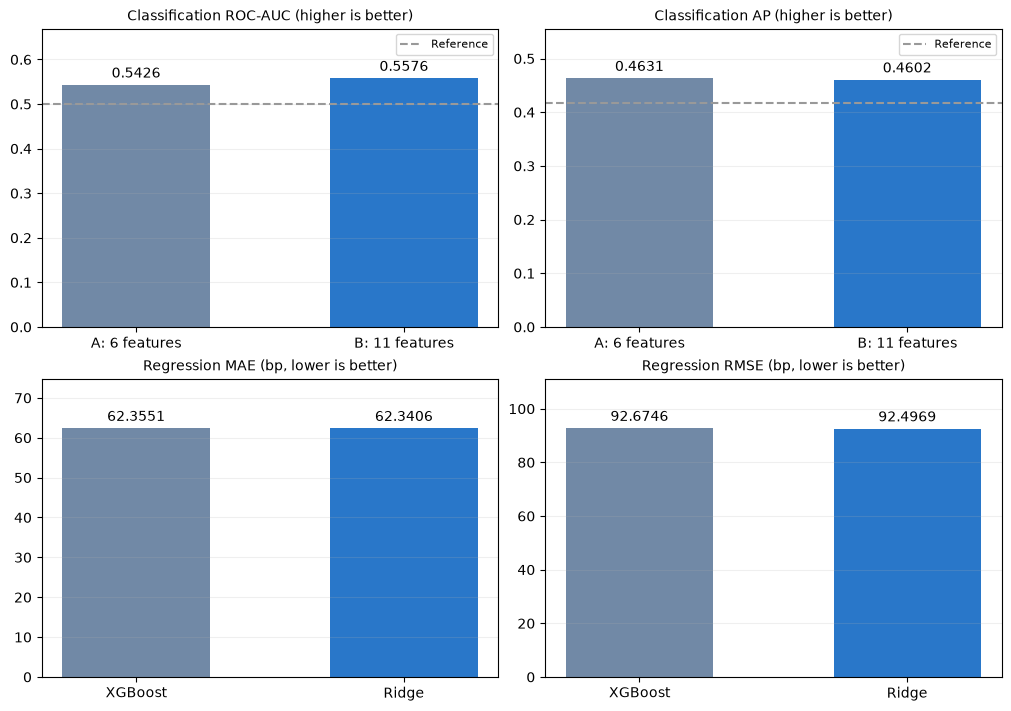

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7), constrained_layout=True)
colors = ["#7189a6", "#2977c9"]
for ax, table, metric, title, labels in (
    (axes[0, 0], classification, "roc_auc", "Classification ROC-AUC (higher is better)", ["A: 6 features", "B: 11 features"]),
    (axes[0, 1], classification, "ap", "Classification AP (higher is better)", ["A: 6 features", "B: 11 features"]),
    (axes[1, 0], regression, "mae_bp", "Regression MAE (bp, lower is better)", ["XGBoost", "Ridge"]),
    (axes[1, 1], regression, "rmse_bp", "Regression RMSE (bp, lower is better)", ["XGBoost", "Ridge"]),
):
    bars = ax.bar(labels, table[metric], color=colors, width=0.55)
    ax.bar_label(bars, fmt="%.4f", padding=3)
    ax.set_title(title, fontsize=10)
    ax.set_ylim(0, max(table[metric]) * 1.2)
    ax.grid(axis="y", alpha=0.2)
    if metric in ("roc_auc", "ap"):
        reference = 0.5 if metric == "roc_auc" else classification.iloc[0]["positive_rate"]
        ax.axhline(reference, color="#999999", linestyle="--", label="Reference")
        ax.legend(fontsize=8)
show_figure(fig, RUN.path / "comparison.png")


## 5. 输出可用于报告的汇总说明


In [5]:
def markdown_table(table):
    """Build a readable Markdown table without extra dependencies."""
    shown = table.copy()
    for column in shown.select_dtypes(include="number").columns:
        shown[column] = shown[column].map(lambda x: f"{x:.6f}" if isinstance(x, float) else str(x))
    lines = ["| " + " | ".join(shown.columns) + " |", "| " + " | ".join(["---"] * len(shown.columns)) + " |"]
    for row in shown.itertuples(index=False, name=None):
        lines.append("| " + " | ".join(str(x) for x in row) + " |")
    return "\n".join(lines)

report = "# Final results comparison\n\n"
report += f"Classification source:`{classification_run.relative_to(ROOT).as_posix()}`\n\n"
report += f"Regression source:`{regression_run.relative_to(ROOT).as_posix()}`\n\n"
report += "## Classification: arms A and B\n\n" + markdown_table(classification[classification_metrics]) + "\n\n"
report += "## Regression: XGBoost and Ridge\n\n" + markdown_table(regression[regression_metrics]) + "\n\n"
report += "## Actual sample splits\n\nClassification:\n\n" + markdown_table(classification_split) + "\n\n"
report += "Regression:\n\n" + markdown_table(regression_split) + "\n\n"
report += "## Metric differences (final − baseline)\n\n" + markdown_table(deltas) + "\n\n"
report += "Returns are shown in bps; 1% = 100 bps. Negative delta_rmse_bp means improvement over the training-mean baseline.\n\n"
report += "Classification changes inputs; regression changes the model. Not all 14 EDA features enter arm B.\n\n"
report += "These single historical holdouts were explored previously; small differences do not establish significance or future performance.\n"
(RUN.path / "final_comparison.md").write_text(report, encoding="utf-8")
save_json(RUN.path / "status.json", {"status": "completed"})
print("Final report:", (RUN.path / "final_comparison.md").relative_to(ROOT))


Final report: output\final_comparison\20261123_220651_400227\final_comparison.md
